In [183]:
import pandas as pd

url = "https://raw.githubusercontent.com/vivekarvind/Machine-Learning-Project---Walmart_Recruiting_Store_Sales_Forecasting/master/train.csv"

df = pd.read_csv(url)

print("Dataset loaded successfully!")
print("Shape:", df.shape)
display(df.head())

Dataset loaded successfully!
Shape: (421570, 5)


,Store,Dept,Date,Weekly_Sales,IsHoliday
0,1,1,2010-02-05,24924.50,False
1,1,1,2010-02-12,46039.49,True
2,1,1,2010-02-19,41595.55,False
3,1,1,2010-02-26,19403.54,False
4,1,1,2010-03-05,21827.90,False


In [184]:
print(df.info())

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 421570 entries, 0 to 421569
Data columns (total 5 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   Store         421570 non-null  int64  
 1   Dept          421570 non-null  int64  
 2   Date          421570 non-null  object 
 3   Weekly_Sales  421570 non-null  float64
 4   IsHoliday     421570 non-null  bool   
dtypes: bool(1), float64(1), int64(2), object(1)
memory usage: 13.3+ MB
None

Missing values:
Store           0
Dept            0
Date            0
Weekly_Sales    0
IsHoliday       0
dtype: int64

Duplicate rows: 0


In [185]:
df['Date'] = pd.to_datetime(df['Date'])

print(df.dtypes)
print("\nDate range:")
print(df['Date'].min(), "to", df['Date'].max())

Store                    int64
Dept                     int64
Date            datetime64[ns]
Weekly_Sales           float64
IsHoliday                 bool
dtype: object

Date range:
2010-02-05 00:00:00 to 2012-10-26 00:00:00


In [186]:
weekly_sales = (
    df.groupby('Date')['Weekly_Sales']
      .sum()
      .reset_index()
      .sort_values('Date')
)

print("Weekly dataset shape:", weekly_sales.shape)
display(weekly_sales.head())

Weekly dataset shape: (143, 2)


,Date,Weekly_Sales
0,2010-02-05,49750740.50
1,2010-02-12,48336677.63
2,2010-02-19,48276993.78
3,2010-02-26,43968571.13
4,2010-03-05,46871470.30


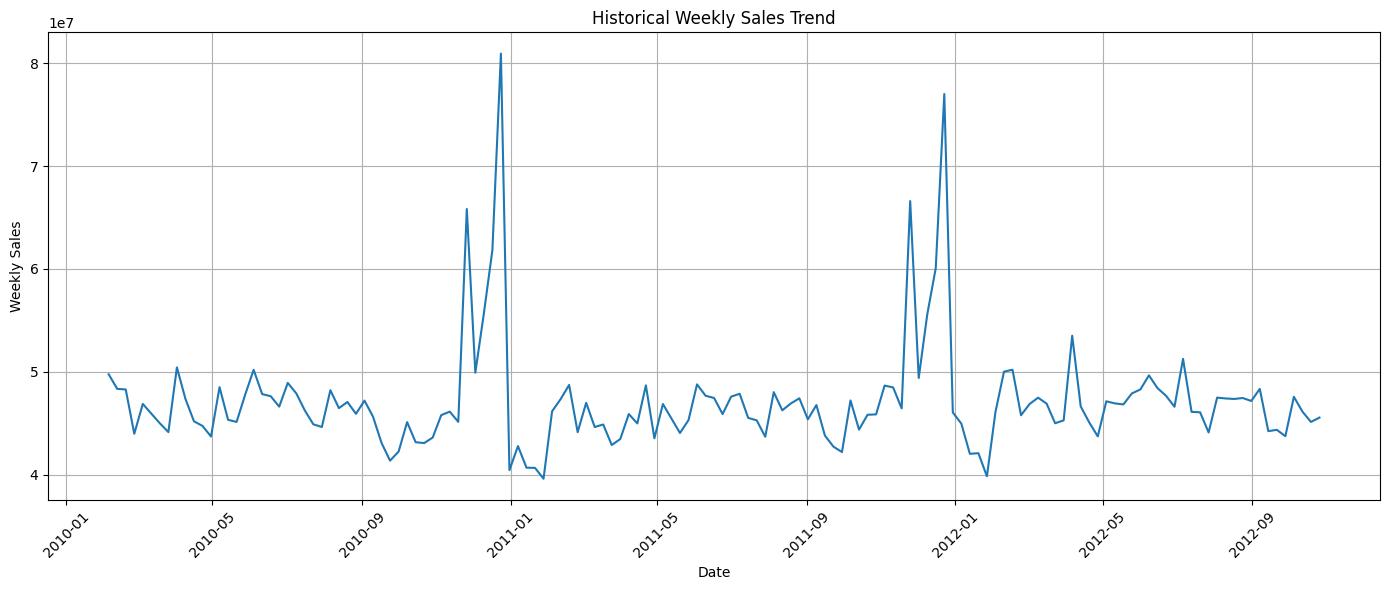

In [187]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

plt.plot(
    weekly_sales['Date'],
    weekly_sales['Weekly_Sales']
)

plt.title('Historical Weekly Sales Trend')
plt.xlabel('Date')
plt.ylabel('Weekly Sales')
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [188]:
# Create lag features
model_data = weekly_sales.copy()

model_data['Lag_1'] = model_data['Weekly_Sales'].shift(1)
model_data['Lag_2'] = model_data['Weekly_Sales'].shift(2)
model_data['Lag_4'] = model_data['Weekly_Sales'].shift(4)

# 4-week moving average using only previous weeks
model_data['Rolling_4'] = (
    model_data['Weekly_Sales']
    .shift(1)
    .rolling(window=4)
    .mean()
)

# Remove rows created by lagging
model_data = model_data.dropna().reset_index(drop=True)

print("Model dataset shape:", model_data.shape)
display(model_data.head())

Model dataset shape: (139, 6)


,Date,Weekly_Sales,Lag_1,Lag_2,Lag_4,Rolling_4
0,2010-03-05,46871470.30,43968571.13,48276993.78,49750740.50,4.758325e+07
1,2010-03-12,45925396.51,46871470.30,43968571.13,48336677.63,4.686343e+07
2,2010-03-19,44988974.64,45925396.51,46871470.30,48276993.78,4.626061e+07
3,2010-03-26,44133961.05,44988974.64,45925396.51,43968571.13,4.543860e+07
4,2010-04-02,50423831.26,44133961.05,44988974.64,46871470.30,4.547995e+07


In [189]:
from sklearn.model_selection import train_test_split

features = ['Lag_1', 'Lag_2', 'Lag_4', 'Rolling_4']
target = 'Weekly_Sales'

X = model_data[features]
y = model_data[target]

split_index = int(len(model_data) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Training period:", model_data['Date'].iloc[0], "to", model_data['Date'].iloc[split_index-1])
print("Testing period:", model_data['Date'].iloc[split_index], "to", model_data['Date'].iloc[-1])

Training samples: 111
Testing samples: 28
Training period: 2010-03-05 00:00:00 to 2012-04-13 00:00:00
Testing period: 2012-04-20 00:00:00 to 2012-10-26 00:00:00


In [190]:
from sklearn.ensemble import RandomForestRegressor

model = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    max_depth=8
)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Model training completed!")
print("Predictions generated:", len(y_pred))

Model training completed!
Predictions generated: 28


In [191]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("Model Evaluation")
print("-----------------")
print(f"MAE  : {mae:,.2f}")
print(f"RMSE : {rmse:,.2f}")
print(f"R²   : {r2:.4f}")

Model Evaluation
-----------------
MAE  : 2,047,903.22
RMSE : 2,638,763.73
R²   : -1.2445


In [192]:
# Create improved forecasting features

improved_data = weekly_sales.copy()

# Holiday information
holiday_data = (
    df.groupby('Date')['IsHoliday']
      .max()
      .reset_index()
)

improved_data = improved_data.merge(
    holiday_data,
    on='Date',
    how='left'
)

# Lag features
for lag in [1, 2, 4, 8, 13, 52]:
    improved_data[f'Lag_{lag}'] = (
        improved_data['Weekly_Sales'].shift(lag)
    )

# Rolling averages using only past data
improved_data['Rolling_4'] = (
    improved_data['Weekly_Sales']
    .shift(1)
    .rolling(4)
    .mean()
)

improved_data['Rolling_8'] = (
    improved_data['Weekly_Sales']
    .shift(1)
    .rolling(8)
    .mean()
)

# Calendar features
improved_data['Month'] = improved_data['Date'].dt.month
improved_data['Quarter'] = improved_data['Date'].dt.quarter
improved_data['Year'] = improved_data['Date'].dt.year

# Remove rows with missing lag values
improved_data = improved_data.dropna().reset_index(drop=True)

print("Improved dataset shape:", improved_data.shape)
display(improved_data.head())

Improved dataset shape: (91, 14)


,Date,Weekly_Sales,IsHoliday,Lag_1,Lag_2,Lag_4,Lag_8,Lag_13,Lag_52,Rolling_4,Rolling_8,Month,Quarter,Year
0,2011-02-04,46153111.12,False,39599852.99,40654648.03,42775787.77,55666770.39,45781981.89,49750740.50,4.092599e+07,5.031943e+07,2,1,2011
1,2011-02-11,47336192.79,True,46153111.12,39599852.99,40673678.04,61820799.85,46124800.83,48336677.63,4.177032e+07,4.913023e+07,2,1,2011
2,2011-02-18,48716164.12,False,47336192.79,46153111.12,40654648.03,80931415.60,45125584.18,48276993.78,4.343595e+07,4.731965e+07,2,1,2011
3,2011-02-25,44125859.84,False,48716164.12,47336192.79,39599852.99,40432519.00,65821003.24,43968571.13,4.545133e+07,4.329274e+07,2,1,2011
4,2011-03-04,46980603.74,False,44125859.84,48716164.12,46153111.12,42775787.77,49909027.88,46871470.30,4.658283e+07,4.375441e+07,3,1,2011


In [193]:
improved_features = [
    'Lag_1',
    'Lag_2',
    'Lag_4',
    'Lag_8',
    'Lag_13',
    'Lag_52',
    'Rolling_4',
    'Rolling_8',
    'Month',
    'Quarter',
    'Year',
    'IsHoliday'
]

X = improved_data[improved_features]
y = improved_data['Weekly_Sales']

split_index = int(len(improved_data) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print(
    "Training period:",
    improved_data['Date'].iloc[0],
    "to",
    improved_data['Date'].iloc[split_index - 1]
)

print(
    "Testing period:",
    improved_data['Date'].iloc[split_index],
    "to",
    improved_data['Date'].iloc[-1]
)

Training samples: 72
Testing samples: 19
Training period: 2011-02-04 00:00:00 to 2012-06-15 00:00:00
Testing period: 2012-06-22 00:00:00 to 2012-10-26 00:00:00


In [194]:
from sklearn.ensemble import RandomForestRegressor

improved_model = RandomForestRegressor(
    n_estimators=300,
    random_state=42,
    max_depth=10
)

improved_model.fit(X_train, y_train)

improved_pred = improved_model.predict(X_test)

print("Improved model training completed!")
print("Predictions generated:", len(improved_pred))

Improved model training completed!
Predictions generated: 19


In [195]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

improved_mae = mean_absolute_error(y_test, improved_pred)
improved_rmse = np.sqrt(mean_squared_error(y_test, improved_pred))
improved_r2 = r2_score(y_test, improved_pred)

print("Improved Model Evaluation")
print("-------------------------")
print(f"MAE  : {improved_mae:,.2f}")
print(f"RMSE : {improved_rmse:,.2f}")
print(f"R²   : {improved_r2:.4f}")

Improved Model Evaluation
-------------------------
MAE  : 1,343,423.02
RMSE : 1,610,618.39
R²   : 0.1618


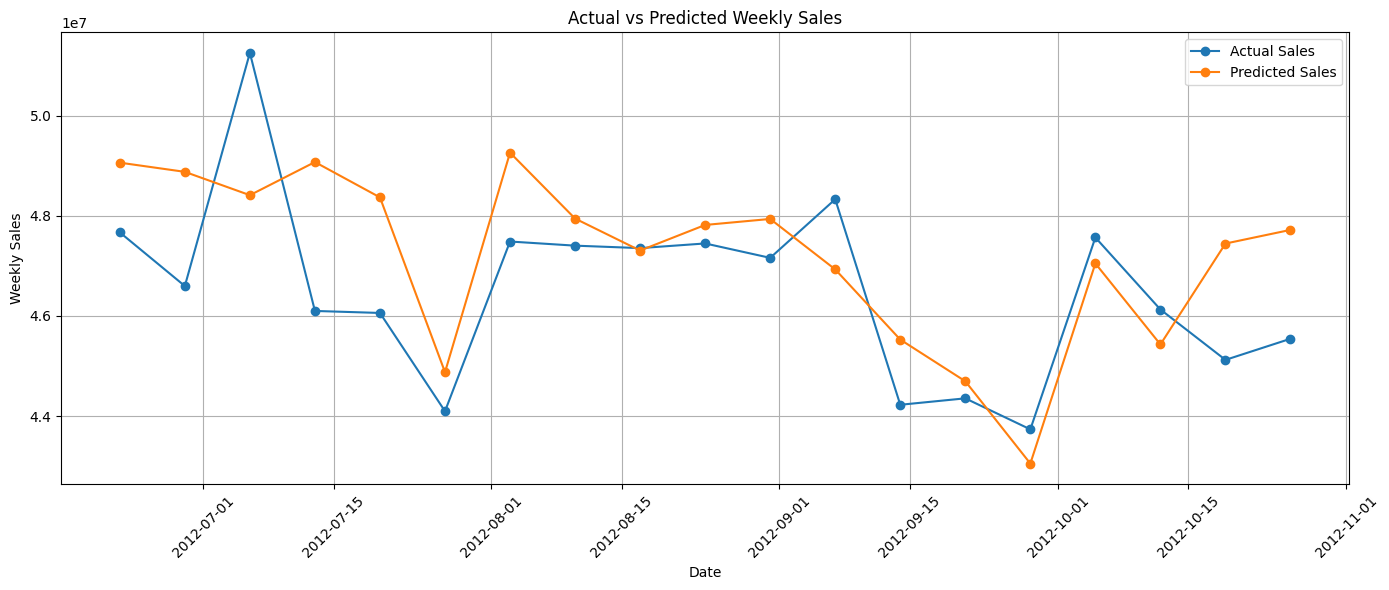

In [196]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

plt.plot(
    improved_data['Date'].iloc[split_index:],
    y_test.values,
    label='Actual Sales',
    marker='o'
)

plt.plot(
    improved_data['Date'].iloc[split_index:],
    improved_pred,
    label='Predicted Sales',
    marker='o'
)

plt.title('Actual vs Predicted Weekly Sales')
plt.xlabel('Date')
plt.ylabel('Weekly Sales')
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [197]:
# Train final model on all available historical data

final_model = RandomForestRegressor(
    n_estimators=300,
    random_state=42,
    max_depth=10
)

X_full = improved_data[improved_features]
y_full = improved_data['Weekly_Sales']

final_model.fit(X_full, y_full)

# Start with the complete historical weekly series
history = weekly_sales.copy()

future_dates = pd.date_range(
    start=history['Date'].max() + pd.Timedelta(weeks=1),
    periods=12,
    freq='7D'
)

future_predictions = []

for future_date in future_dates:

    sales_values = history['Weekly_Sales'].tolist()

    features_row = {
        'Lag_1': sales_values[-1],
        'Lag_2': sales_values[-2],
        'Lag_4': sales_values[-4],
        'Lag_8': sales_values[-8],
        'Lag_13': sales_values[-13],
        'Lag_52': sales_values[-52],
        'Rolling_4': sum(sales_values[-4:]) / 4,
        'Rolling_8': sum(sales_values[-8:]) / 8,
        'Month': future_date.month,
        'Quarter': future_date.quarter,
        'Year': future_date.year,
        'IsHoliday': False
    }

    input_data = pd.DataFrame([features_row])

    prediction = final_model.predict(input_data)[0]
    future_predictions.append(prediction)

    # Add prediction to history for next recursive forecast
    history = pd.concat([
        history,
        pd.DataFrame({
            'Date': [future_date],
            'Weekly_Sales': [prediction]
        })
    ], ignore_index=True)

forecast = pd.DataFrame({
    'Date': future_dates,
    'Predicted_Sales': future_predictions
})

print("12-Week Future Forecast")
display(forecast)

12-Week Future Forecast


,Date,Predicted_Sales
0,2012-11-02,4.775526e+07
1,2012-11-09,4.769334e+07
2,2012-11-16,4.694022e+07
3,2012-11-23,6.244148e+07
4,2012-11-30,4.915514e+07
5,2012-12-07,5.274209e+07
6,2012-12-14,5.860619e+07
7,2012-12-21,6.743315e+07
8,2012-12-28,4.979432e+07
9,2013-01-04,4.818079e+07


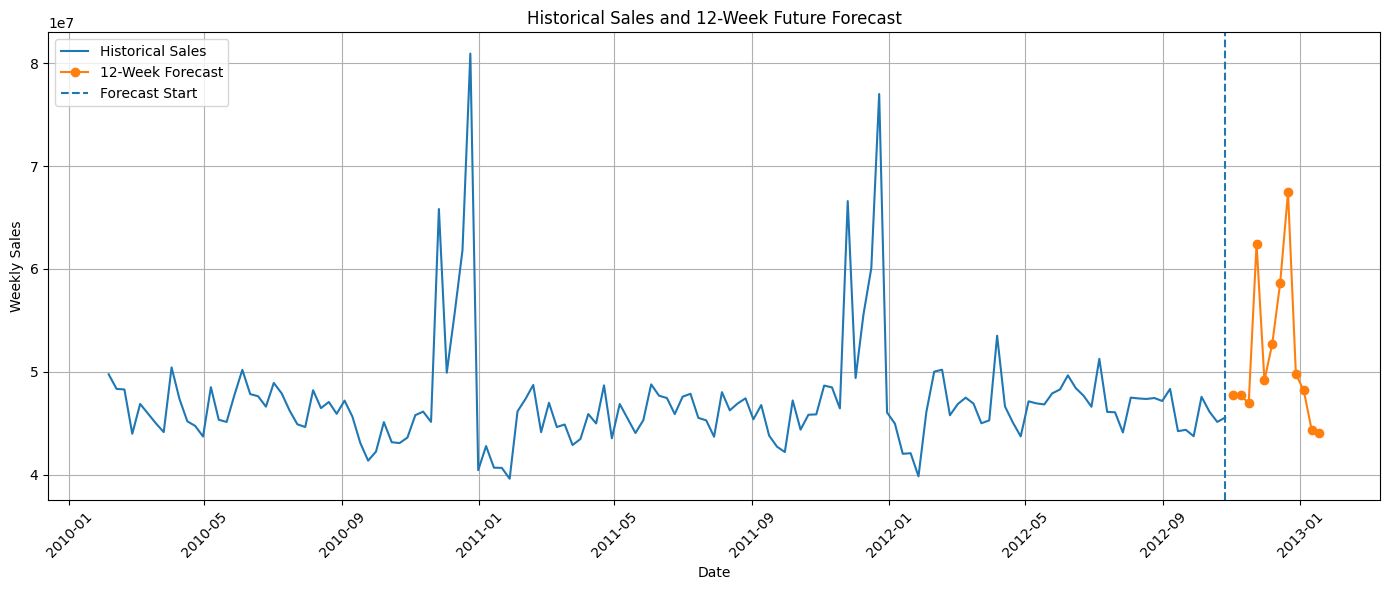

In [198]:
plt.figure(figsize=(14, 6))

plt.plot(
    weekly_sales['Date'],
    weekly_sales['Weekly_Sales'],
    label='Historical Sales'
)

plt.plot(
    forecast['Date'],
    forecast['Predicted_Sales'],
    label='12-Week Forecast',
    marker='o'
)

plt.axvline(
    weekly_sales['Date'].max(),
    linestyle='--',
    label='Forecast Start'
)

plt.title('Historical Sales and 12-Week Future Forecast')
plt.xlabel('Date')
plt.ylabel('Weekly Sales')
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [199]:
comparison = pd.DataFrame({
    'Model': [
        'Initial Random Forest',
        'Improved Seasonal Random Forest'
    ],
    'MAE': [
        mae,
        improved_mae
    ],
    'RMSE': [
        rmse,
        improved_rmse
    ],
    'R2': [
        r2,
        improved_r2
    ]
})

display(comparison)

,Model,MAE,RMSE,R2
0,Initial Random Forest,2.047903e+06,2.638764e+06,-1.244453
1,Improved Seasonal Random Forest,1.343423e+06,1.610618e+06,0.161763


In [200]:
print("KEY PROJECT INSIGHTS")
print("====================")

print("1. The dataset contains 421,570 historical sales records.")
print("2. Historical weekly sales show noticeable fluctuations and seasonal spikes.")
print("3. The initial Random Forest model performed poorly with R² = -1.2445.")
print("4. Adding seasonal lag features and rolling averages improved performance.")
print("5. The improved model achieved R² = 0.1618.")
print("6. The improved model reduced MAE and RMSE compared with the initial model.")
print("7. A 12-week future sales forecast was generated using the final model.")

KEY PROJECT INSIGHTS
1. The dataset contains 421,570 historical sales records.
2. Historical weekly sales show noticeable fluctuations and seasonal spikes.
3. The initial Random Forest model performed poorly with R² = -1.2445.
4. Adding seasonal lag features and rolling averages improved performance.
5. The improved model achieved R² = 0.1618.
6. The improved model reduced MAE and RMSE compared with the initial model.
7. A 12-week future sales forecast was generated using the final model.


In [201]:
forecast.to_csv('walmart_12_week_forecast.csv', index=False)

print("Forecast file saved successfully!")
print("File: walmart_12_week_forecast.csv")

Forecast file saved successfully!
File: walmart_12_week_forecast.csv


In [202]:
model_data.to_csv('walmart_processed_data.csv', index=False)

print("Processed dataset saved successfully!")
print("File: walmart_processed_data.csv")

Processed dataset saved successfully!
File: walmart_processed_data.csv
